In [3]:
%matplotlib widget

In [1]:
%%capture
from ocelot import *
from ocelot.gui import *
import matplotlib.pyplot as plt
import numpy as np
import latdraw
from felarc.family import (get_isochronous_dispersions_at_middle_dipole_entrance, 
                           get_quad_strengths,
                           ArcDefinition, 
                           make_arc,
                           make_arc_to_inner_dipole_start)
from felarc.t20 import ARC_ANGLE_RAD

IndentationError: unindent does not match any outer indentation level (family.py, line 102)

The isochronous condition is given by $\int \frac{D(s)}{\rho(s)} \, \mathrm{d}s = 0$.
So in the most simple implementation: you offset the $\frac{D}{\rho}$ in the first and last dipoles with opposite-signed $\frac{D}{\rho}$ in the middle dipole.  The only way to do this is with quadrupoles inbetween to focus the dispersive trajectory so that its sign is flipped. 

# Introduction
Let's start with defining a simple isochronous arc.


$D_j = \rho_2\left [ D_j' \cot{(\phi_2) + 1} \right ]$

$D'_j = -\frac{\rho_1}{\rho_2} \left ( \frac{3}{2} \phi_1 - \sin\phi_1 \right )$

In [79]:
MAGNET_ANGLE_RAD = 0.01 * 4
MAGNET_LENGTH = 2
dx, dxp = get_isochronous_dispersions_at_middle_dipole_entrance(MAGNET_ANGLE_RAD, MAGNET_LENGTH,
                                                                MAGNET_ANGLE_RAD, MAGNET_LENGTH)
print(f"Consider an arc consisting of three identical dipoles, L = {MAGNET_LENGTH}m, ANGLE = {MAGNET_ANGLE_RAD}rad")
print(f"To achieve an isochronous arc we need at the entrance to the middle dipole, DX = {dx:3g}m and DX' = {dxp:3g}rad")

Consider an arc consisting of three identical dipoles, L = 2m, ANGLE = 0.04rad
To achieve an isochronous arc we need at the entrance to the middle dipole, DX = -0.0199941m and DX' = -0.0200107rad


So we need to introduce quadrupoles to achieve the necessary dispersions at the entrance to the middle dipole.  
I will just use ocelot's `match` function in combination with two quads separated by 1m.

In [80]:
bd_arc = ArcDefinition(MAGNET_ANGLE_RAD,
                       MAGNET_LENGTH,
                       MAGNET_ANGLE_RAD,
                       MAGNET_LENGTH,
                       l1=1,
                       l2=1,
                       l3=1,
                       quad_length=1,
                       k1_outer=1.0,
                       k1_inner=-0.1
                       )
                
bd_arc = get_quad_strengths(bd_arc)
print(f"{bd_arc.k1_outer = }, {bd_arc.k1_inner = }")
print(bd_arc)

initial value: x =  [1.0, -0.1]
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 91
         Function evaluations: 174
bd_arc.k1_outer = np.float64(1.0237286787718811), bd_arc.k1_inner = np.float64(-2.2692910457805873)
ArcDefinition(outer_angle=0.04, outer_length=2, inner_angle=0.04, inner_length=2, l1=1, l2=1, l3=1, quad_length=1, k1_outer=np.float64(1.0237286787718811), k1_inner=np.float64(-2.2692910457805873))


In [81]:
mlat = make_arc_to_inner_dipole_start(bd_arc)
print(bd_arc)

ArcDefinition(outer_angle=0.04, outer_length=2, inner_angle=0.04, inner_length=2, l1=1, l2=1, l3=1, quad_length=1, k1_outer=np.float64(1.0237286787718811), k1_inner=np.float64(-2.2692910457805873))


-0.01999413323449864 -0.020010671376770622


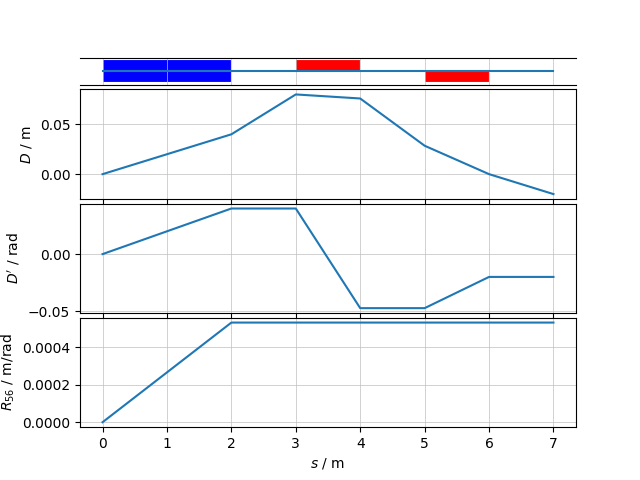

In [82]:
tws0 = Twiss(beta_x = 20, beta_y = 10)
df = twiss(mlat, tws0, return_df=True)
print(df.iloc[-1].Dx, df.iloc[-1].Dxp)
seq = latdraw.interfaces.lattice_from_ocelot(mlat.sequence)
fig, (_, ax1, ax2, ax3) = latdraw.subplots_with_lattices([seq, None, None, None])
ax1.plot(df.s, df.Dx)
ax2.plot(df.s, df.Dxp)
ax3.set_xlabel("$s$ / m")
ax2.set_ylabel("$D'$ / rad")
ax3.set_ylabel("$R_{56}$ / m/rad")
ax1.set_ylabel("$D$ / m")
_, Rs, _, s = mlat.transfer_maps(energy=14, output_at_each_step=True)
ax3.plot(s, [R[4,5] for R in Rs])

#print(R[4,5])

ArcDefinition(outer_angle=0.04, outer_length=2, inner_angle=0.04, inner_length=2, l1=1, l2=1, l3=1, quad_length=1, k1_outer=np.float64(1.0237286787718811), k1_inner=np.float64(-2.2692910457805873))
1.0201462758568924e-07 9.087481230712902e-08
FINAL R56: -2.1078908832490063e-08


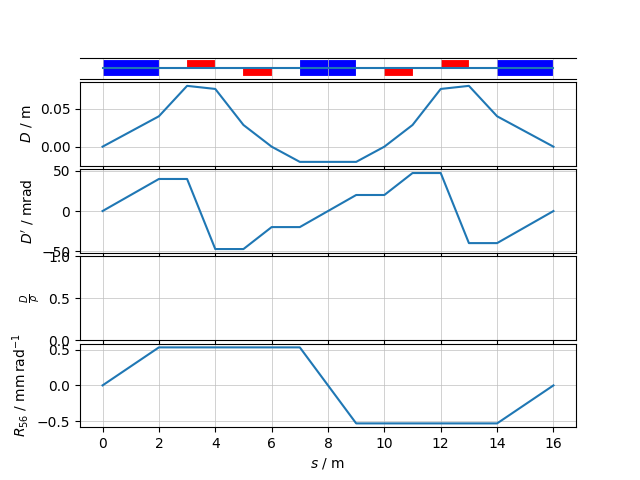

In [85]:

mlat = make_arc(bd_arc)
print(bd_arc)
df = twiss(mlat, tws0, return_df=True)
twisses_periodic = twiss(mlat, tws0=tws0)
print(df.iloc[-1].Dx, df.iloc[-1].Dxp)
ocelat = latdraw.interfaces.lattice_from_ocelot(mlat.sequence)
fig, (_, ax1, ax2, ax4, ax3) = latdraw.subplots_with_lattice(ocelat, nrows=4)
ax1.plot(df.s, df.Dx)
ax2.plot(df.s, df.Dxp*1e3)
ax3.set_xlabel("$s$ / m")
ax2.set_ylabel("$D'$ / mrad")
ax3.set_ylabel(r"$R_{56}$ / $\mathrm{mm\,rad^{-1}}$")
ax4.set_ylabel(r"$\frac{D}{\rho}$")
ax1.set_ylabel("$D$ / m")
_, Rs, _, s = mlat.transfer_maps(energy=14, output_at_each_step=True)
ax3.plot(s, [R[4,5]*1e3 for R in Rs])
print(f"FINAL R56: {Rs[-1][4,5]}")

[<ocelot.cpbd.beam.Twiss object at 0x130cce5a0>, <ocelot.cpbd.beam.Twiss object at 0x1308e2030>, <ocelot.cpbd.beam.Twiss object at 0x131031d00>, <ocelot.cpbd.beam.Twiss object at 0x12ff19370>, <ocelot.cpbd.beam.Twiss object at 0x131315940>, <ocelot.cpbd.beam.Twiss object at 0x1312b51c0>, <ocelot.cpbd.beam.Twiss object at 0x12f1d29f0>, <ocelot.cpbd.beam.Twiss object at 0x13126fce0>, <ocelot.cpbd.beam.Twiss object at 0x131182930>, <ocelot.cpbd.beam.Twiss object at 0x12f5fa390>, <ocelot.cpbd.beam.Twiss object at 0x12f1d3920>, <ocelot.cpbd.beam.Twiss object at 0x13125ac60>, <ocelot.cpbd.beam.Twiss object at 0x13125b680>, <ocelot.cpbd.beam.Twiss object at 0x1312595e0>, <ocelot.cpbd.beam.Twiss object at 0x13138c860>, <ocelot.cpbd.beam.Twiss object at 0x1300bf0e0>, <ocelot.cpbd.beam.Twiss object at 0x13138c590>, <ocelot.cpbd.beam.Twiss object at 0x1312effe0>, <ocelot.cpbd.beam.Twiss object at 0x1312ef6e0>, <ocelot.cpbd.beam.Twiss object at 0x130ef2a20>]


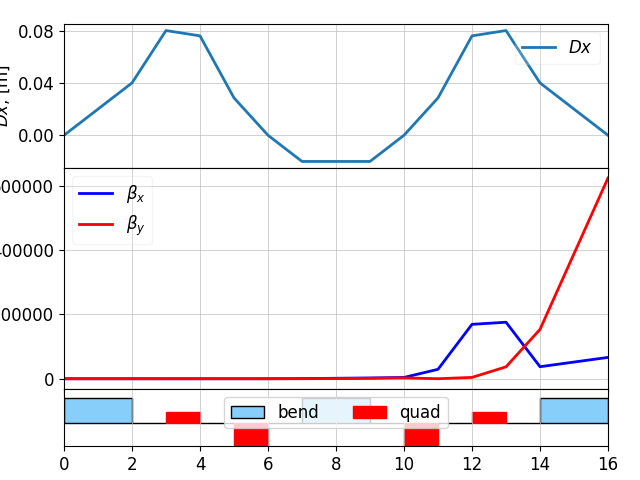

In [86]:
print(twisses_periodic)
plot_opt_func(mlat, twisses_periodic)